In [14]:
!pip install -q datasets wandb
import os
import sys
import time
import json
import datetime
import tqdm
import math
from rich.progress import Console, track
from zoneinfo import ZoneInfo
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk import pos_tag
from nltk.corpus import words, wordnet, stopwords
from nltk.tokenize import word_tokenize, wordpunct_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from datasets import load_from_disk
from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.trainers import WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace
import datasets
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, Subset, DataLoader
import wandb
nltk.download(
    [
        "words",
        "wordnet",
        "stopwords",
        "punkt",
        "punkt_tab",
        "averaged_perceptron_tagger"
    ]
)
plt.style.use('dark_background')

[nltk_data] Downloading package words to /usr/share/nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [3]:
dataset_path = r"/kaggle/input/datasets/mithileshnakade/fineweb-edu-random-samples/random_sample_10k/random_sample_10k"
selected_dataset = datasets.load_from_disk(dataset_path)
dataset_texts = selected_dataset["text"]
dataset_texts_lower = [text.lower() for text in dataset_texts]
total_corpus = "[SEP]".join(dataset_texts_lower)

# tokens = wordpunct_tokenize(total_corpus)
# vocab = set(tokens)

special_tokens = ["[UNK]", "[CLS]", "[SEP]", "[PAD]", "[MASK]"]

tokenizer = Tokenizer(WordPiece(unk_token="[UNK]"))
tokenizer.pre_tokenizer = Whitespace()

trainer = WordPieceTrainer(
    vocab_size=55000,
    special_tokens=special_tokens
)

tokenizer.train_from_iterator(total_corpus.split("."), trainer)

output = tokenizer.encode(total_corpus)

tokens = output.tokens
vocab = set(output.tokens)

token2idx = {token: idx for idx, token in enumerate(vocab)}
idx2token = {idx: token for idx, token in enumerate(vocab)}

print(f"Token count: {len(tokens)}")
print(f"Vocab size: {len(vocab)}")




Token count: 9427539
Vocab size: 51700


In [4]:
# model_data = {
#     "tokens": tokens,
#     "vocab": list(vocab),
#     "vocab_size": len(vocab),
#     "token2idx": token2idx,
#     "idx2token": idx2token
# }

# with open(r"/content/us-politics-textgen-model-data.json", "w") as f:
#     json.dump(model_data, f)
# drive_model_data_json_path = src_dir + "/us-politics-textgen-model-data.json"
# !cp "/content/us-politics-textgen-model-data.json" "{drive_model_data_json_path}"

In [5]:
data_size = len(tokens)
# data_size = 256*100
context_window = 64

sample_corpus = tokens[:data_size]
corpus_encodings = [token2idx[token] for token in sample_corpus if token in token2idx]

input_list = []
target_list = []

for n in range(0, len(sample_corpus)-(context_window+1), context_window):
    input_enc = corpus_encodings[n : n+context_window]
    target_enc = corpus_encodings[n+1 : n+context_window+1]
    input_list.append(input_enc)
    target_list.append(target_enc)

input_enc_tensor = torch.tensor(np.array(input_list, dtype=np.int32), dtype=torch.long)
target_enc_tensor = torch.tensor(np.array(target_list, dtype=np.int32), dtype=torch.long)

print(f"Input shape: {input_enc_tensor.shape}")
print(f"Target shape: {target_enc_tensor.shape}")

Input shape: torch.Size([147305, 64])
Target shape: torch.Size([147305, 64])


In [6]:
class MyDataset(Dataset):
    def __init__(self, X: torch.Tensor, y: torch.Tensor):
        self.input_embeddings = X
        self.target_embeddings = y

    def __len__(self):
        return len(self.input_embeddings)

    def __getitem__(self, idx: int):
        input_tensor = self.input_embeddings[idx]
        target_tensor = self.target_embeddings[idx]

        return input_tensor, target_tensor

training_size = int(input_enc_tensor.size(0) * 0.85)
remaining_size = int(input_enc_tensor.size(0) - training_size)
validation_size = int(remaining_size * 0.40)
testing_size = int(remaining_size - validation_size)

training_input_enc = input_enc_tensor[:training_size]
training_target_enc = target_enc_tensor[:training_size]

validation_input_enc = input_enc_tensor[training_size:training_size+validation_size]
validation_target_enc = target_enc_tensor[training_size:training_size+validation_size]

testing_input_enc = input_enc_tensor[training_size+validation_size:training_size+validation_size+testing_size]
testing_target_enc = target_enc_tensor[training_size+validation_size:training_size+validation_size+testing_size]

training_batch_size = 32
validation_batch_size = 32
testing_batch_size = 32

training_dataset = MyDataset(training_input_enc, training_target_enc)
training_dataloader = DataLoader(dataset=training_dataset, batch_size=training_batch_size, shuffle=True, num_workers=2)

validation_dataset = MyDataset(validation_input_enc, validation_target_enc)
validation_dataloader = DataLoader(dataset=validation_dataset, batch_size=validation_batch_size, shuffle=True, num_workers=2)

testing_dataset = MyDataset(testing_input_enc, testing_target_enc)
testing_dataloader = DataLoader(dataset=testing_dataset, batch_size=testing_batch_size, shuffle=True, num_workers=2)

print(f"training_dataset size: {len(training_dataset)}")
print(f"validation_dataset size: {len(validation_dataset)}")
print(f"testing_dataset size: {len(testing_dataset)}")
print(f"training_dataloader batch count: {len(training_dataloader)}")
print(f"validation_dataloader batch count: {len(validation_dataloader)}")
print(f"testing_dataloader batch count: {len(testing_dataloader)}")

training_dataset size: 125209
validation_dataset size: 8838
testing_dataset size: 13258
training_dataloader batch count: 3913
validation_dataloader batch count: 277
testing_dataloader batch count: 415


In [7]:
class MyTorchLayerTransformerModel(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        enc_nheads: int,
        dec_nheads: int,
        d_model: int = 512,
        enable_enc_embed: bool = False,
        max_seq_len: int = 5000,
        pad_idx: int = None
    ):
        super().__init__()

        self.d_model = d_model
        self.enable_enc_embed = enable_enc_embed
        self.pad_idx = pad_idx

        if self.enable_enc_embed:
            self.enc_embedding_layer = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.dec_embedding_layer = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)

        # Precompute positional encodings once and register as a non-trainable buffer
        pe = self._build_pos_encodings(max_seq_len, d_model)
        self.register_buffer("pe", pe)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=enc_nheads,
            activation="gelu",
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(encoder_layer=encoder_layer, num_layers=2)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=dec_nheads,
            activation="gelu",
            batch_first=True
        )

        self.decoder = nn.TransformerDecoder(decoder_layer=decoder_layer, num_layers=1)

        self.classifier_fc = nn.Linear(in_features=d_model, out_features=vocab_size)

    def _build_pos_encodings(self, max_seq_len: int, d_model: int):
        pe = torch.zeros(max_seq_len, d_model)
        position = torch.arange(0, max_seq_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)  # Shape: (1, max_seq_len, d_model)

    def forward(self, Xsrc: torch.Tensor, Xtgt: torch.Tensor):
        # 1. Encoder Embeddings + Positional Encoding
        if self.enable_enc_embed:
            Xsrc_embeddings = self.enc_embedding_layer(Xsrc) * math.sqrt(self.d_model)
        else:
            Xsrc_embeddings = Xsrc

        src_seq_len = Xsrc_embeddings.size(1)
        Xsrc_embeddings = Xsrc_embeddings + self.pe[:, :src_seq_len, :]

        # 2. Decoder Embeddings + Positional Encoding
        Xtgt_embeddings = self.dec_embedding_layer(Xtgt) * math.sqrt(self.d_model)
        tgt_seq_len = Xtgt_embeddings.size(1)
        Xtgt_embeddings = Xtgt_embeddings + self.pe[:, :tgt_seq_len, :]

        # 3. Causal Mask for Decoder
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(tgt_seq_len, device=Xtgt.device)

        # 4. Optional Padding Masks (if pad_idx is set)
        src_pad_mask = (Xsrc == self.pad_idx) if (self.pad_idx is not None and self.enable_enc_embed) else None
        tgt_pad_mask = (Xtgt == self.pad_idx) if (self.pad_idx is not None) else None

        # 5. Forward Pass through Transformer Encoder & Decoder
        H_enc = self.encoder(Xsrc_embeddings, src_key_padding_mask=src_pad_mask)

        H_dec = self.decoder(
            tgt=Xtgt_embeddings,
            memory=H_enc,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_pad_mask,
            memory_key_padding_mask=src_pad_mask
        )

        logits = self.classifier_fc(H_dec)
        return logits

In [8]:
# from kaggle_secrets import UserSecretsClient
# user_secrets = UserSecretsClient()
# wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")
# os.environ["WANDB_API_KEY"] = wandb_api_key
# wandb.login()

# now_uuid = "UTC-"+datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
# # Start a new wandb run to track this script.
# run = wandb.init(
#     # Set the wandb entity where your project will be logged (generally your team name).
#     entity="personal-org-1",
#     # Set the wandb project where this run will be logged.
#     project="Kaggle-Transformer-Pretraining",
#     # name for unique identification
#     name=now_uuid,
#     # Track hyperparameters and run metadata.
#     config={
#         "learning_rate": 1e-3,
#         "architecture": "Encoder-Decoder Transformer",
#         "dataset": "FineWeb-Edu",
#         "epochs": 10,
#     },
# )

# wandb.define_metric("epoch")
# wandb.define_metric("train/*", step_metric="epoch")
# wandb.define_metric("val/*", step_metric="epoch")

In [9]:
n_embd = 256 * 3
n_head = 12

model = MyTorchLayerTransformerModel(
    vocab_size=len(vocab),
    enc_nheads=n_head,
    dec_nheads=n_head,
    d_model=n_embd,
    enable_enc_embed=True
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=0.01)

num_epochs = 15

metrics = {
    "train": {"epochs": [], "losses": [], "accuracies": [], "grad_norms": []},
    "validation": {"epochs": [], "losses": [], "accuracies": [], "grad_norms": []}
}

start_time = time.time()

for epoch in range(num_epochs):
    epoch_loss, epoch_accuracy, epoch_grad_norm = 0.0, 0.0, 0.0
    validation_loss, validation_accuracy, validation_grad_norm = 0.0, 0.0, 0.0

    model.train()
    for Xsrc, Xtgt in tqdm.tqdm(training_dataloader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
        Xsrc = Xsrc.to(device)
        Xtgt = Xtgt.to(device)

        Xdec = Xtgt[:, :-1]
        y_train = Xtgt[:, 1:]

        logits = model(Xsrc, Xdec)
        logits_flattened = logits.reshape(-1, len(vocab))
        y_train_flattened = y_train.reshape(-1)

        loss = criterion(logits_flattened, y_train_flattened)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            predictions = torch.argmax(logits_flattened, dim=-1)
            accuracy = (predictions == y_train_flattened).float().mean().item()

            # Compute L2 gradient norm across all parameters
            sq_grad_norm = sum(
                p.grad.norm(2).item() ** 2 for p in model.parameters() if p.grad is not None
            )
            batch_grad_norm = np.sqrt(sq_grad_norm)

            epoch_loss += loss.item()
            epoch_accuracy += accuracy
            epoch_grad_norm += batch_grad_norm

    model.eval()
    for Xsrc, Xtgt in tqdm.tqdm(validation_dataloader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
        Xsrc = Xsrc.to(device)
        Xtgt = Xtgt.to(device)

        Xdec = Xtgt[:, :-1]
        y_train = Xtgt[:, 1:]

        logits = model(Xsrc, Xdec)
        logits_flattened = logits.reshape(-1, len(vocab))
        y_train_flattened = y_train.reshape(-1)

        loss = criterion(logits_flattened, y_train_flattened)

        with torch.no_grad():
            predictions = torch.argmax(logits_flattened, dim=-1)
            accuracy = (predictions == y_train_flattened).float().mean().item()

            # Compute L2 gradient norm across all parameters
            sq_grad_norm = sum(
                p.grad.norm(2).item() ** 2 for p in model.parameters() if p.grad is not None
            )
            batch_grad_norm = np.sqrt(sq_grad_norm)

            validation_loss += loss.item()
            validation_accuracy += accuracy
            validation_grad_norm += batch_grad_norm

    train_num_batches = len(training_dataloader)
    mean_train_loss = epoch_loss / train_num_batches
    mean_train_accuracy = epoch_accuracy / train_num_batches
    mean_train_grad_norm = epoch_grad_norm / train_num_batches

    validation_num_batches = len(validation_dataloader)
    mean_validation_loss = validation_loss / validation_num_batches
    mean_validation_accuracy = validation_accuracy / validation_num_batches
    mean_validation_grad_norm = validation_grad_norm / validation_num_batches

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {mean_train_loss:.4f} | "
        f"Accuracy: {mean_train_accuracy * 100:.2f}% | "
        f"GradNorm: {mean_train_grad_norm:.4f}"
    )

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {mean_validation_loss:.4f} | "
        f"Accuracy: {mean_validation_accuracy * 100:.2f}% | "
        f"GradNorm: {mean_validation_grad_norm:.4f}"
    )

    metrics["train"]["epochs"].append(epoch)
    metrics["train"]["losses"].append(mean_train_loss)
    metrics["train"]["accuracies"].append(mean_train_accuracy)
    metrics["train"]["grad_norms"].append(mean_train_grad_norm)
    
    metrics["validation"]["epochs"].append(epoch)
    metrics["validation"]["losses"].append(mean_train_loss)
    metrics["validation"]["accuracies"].append(mean_train_accuracy)
    metrics["validation"]["grad_norms"].append(mean_train_grad_norm)

total_time = time.time() - start_time
mins, secs = divmod(total_time, 60)
print(f"\nTraining complete in {mins:.0f}m {secs:.2f}s ({total_time:.2f}s total)")

Epoch 1/15: 100%|██████████| 277/277 [00:22<00:00, 12.24it/s]


Epoch 1/15 | Loss: 7.1151 | Accuracy: 9.40% | GradNorm: 1.6571
Epoch 1/15 | Loss: 6.8787 | Accuracy: 11.92% | GradNorm: 1.6666


Epoch 2/15: 100%|██████████| 277/277 [00:22<00:00, 12.21it/s]


Epoch 2/15 | Loss: 6.7599 | Accuracy: 12.50% | GradNorm: 2.0848
Epoch 2/15 | Loss: 6.7388 | Accuracy: 12.86% | GradNorm: 2.2271


Epoch 3/15: 100%|██████████| 277/277 [00:22<00:00, 12.25it/s]


...

Epoch 13/15 | Loss: 6.7127 | Accuracy: 12.89% | GradNorm: 2.6025
Epoch 13/15 | Loss: 6.7329 | Accuracy: 13.16% | GradNorm: 2.4964


Epoch 14/15: 100%|██████████| 277/277 [00:22<00:00, 12.21it/s]


Epoch 14/15 | Loss: 6.7216 | Accuracy: 12.92% | GradNorm: 2.5036
Epoch 14/15 | Loss: 6.7429 | Accuracy: 13.10% | GradNorm: 2.6714


Epoch 15/15: 100%|██████████| 277/277 [00:22<00:00, 12.23it/s]

Epoch 15/15 | Loss: 6.7202 | Accuracy: 12.92% | GradNorm: 2.4884
Epoch 15/15 | Loss: 6.7348 | Accuracy: 13.11% | GradNorm: 2.7828

Training complete in 271m 30.66s (16290.66s total)


In [11]:
.eval()
test_loss, test_accuracy = 0.0, 0.0

with torch.no_grad():
    for Xsrc, Xtgt in tqdm.tqdm(testing_dataloader, desc="Running test batches..."):
        Xsrc = Xsrc.to(device)
        Xtgt = Xtgt.to(device)

        Xdec = Xtgt[:, :-1]
        y_test = Xtgt[:, 1:]

        logits = model(Xsrc, Xdec)
        logits_flattened = logits.reshape(-1, len(vocab))
        y_test_flattened = y_test.reshape(-1)

        loss = criterion(logits_flattened, y_test_flattened)

        predictions = torch.argmax(logits_flattened, dim=-1)
        accuracy = (predictions == y_test_flattened).float().mean().item()

        test_loss += loss.item()
        test_accuracy += accuracy

num_test_batches = len(testing_dataloader)
mean_test_loss = test_loss / num_test_batches
mean_test_accuracy = test_accuracy / num_test_batches

print(
    f"Test Results | "
    f"Loss: {mean_test_loss:.4f} | "
    f"Accuracy: {mean_test_accuracy * 100:.2f}%"
)

Running test batches...: 100%|██████████| 415/415 [00:31<00:00, 13.13it/s]

Test Results | Loss: 6.7569 | Accuracy: 12.92%


In [21]:
model_y_pred = predictions.detach().cpu().numpy()
model_y_true = y_test_flattened.detach().cpu().numpy()

precision = precision_score(y_true=model_y_true, y_pred=model_y_pred, average="weighted")
recall = recall_score(y_true=model_y_true, y_pred=model_y_pred, average="weighted")
f1 = f1_score(y_true=model_y_true, y_pred=model_y_pred, average="weighted")
print(f"Metrics | Accuracy: {accuracy} | Precision: {precision} | Recall: {recall} | f1: {f1}")

Metrics | Accuracy: 0.14761904761904762 | Precision: 0.0596239382741382 | Recall: 0.14761904761904762 | f1: 0.0755447765092872


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Model capacity: 138074356 or 138.074356 million parameters


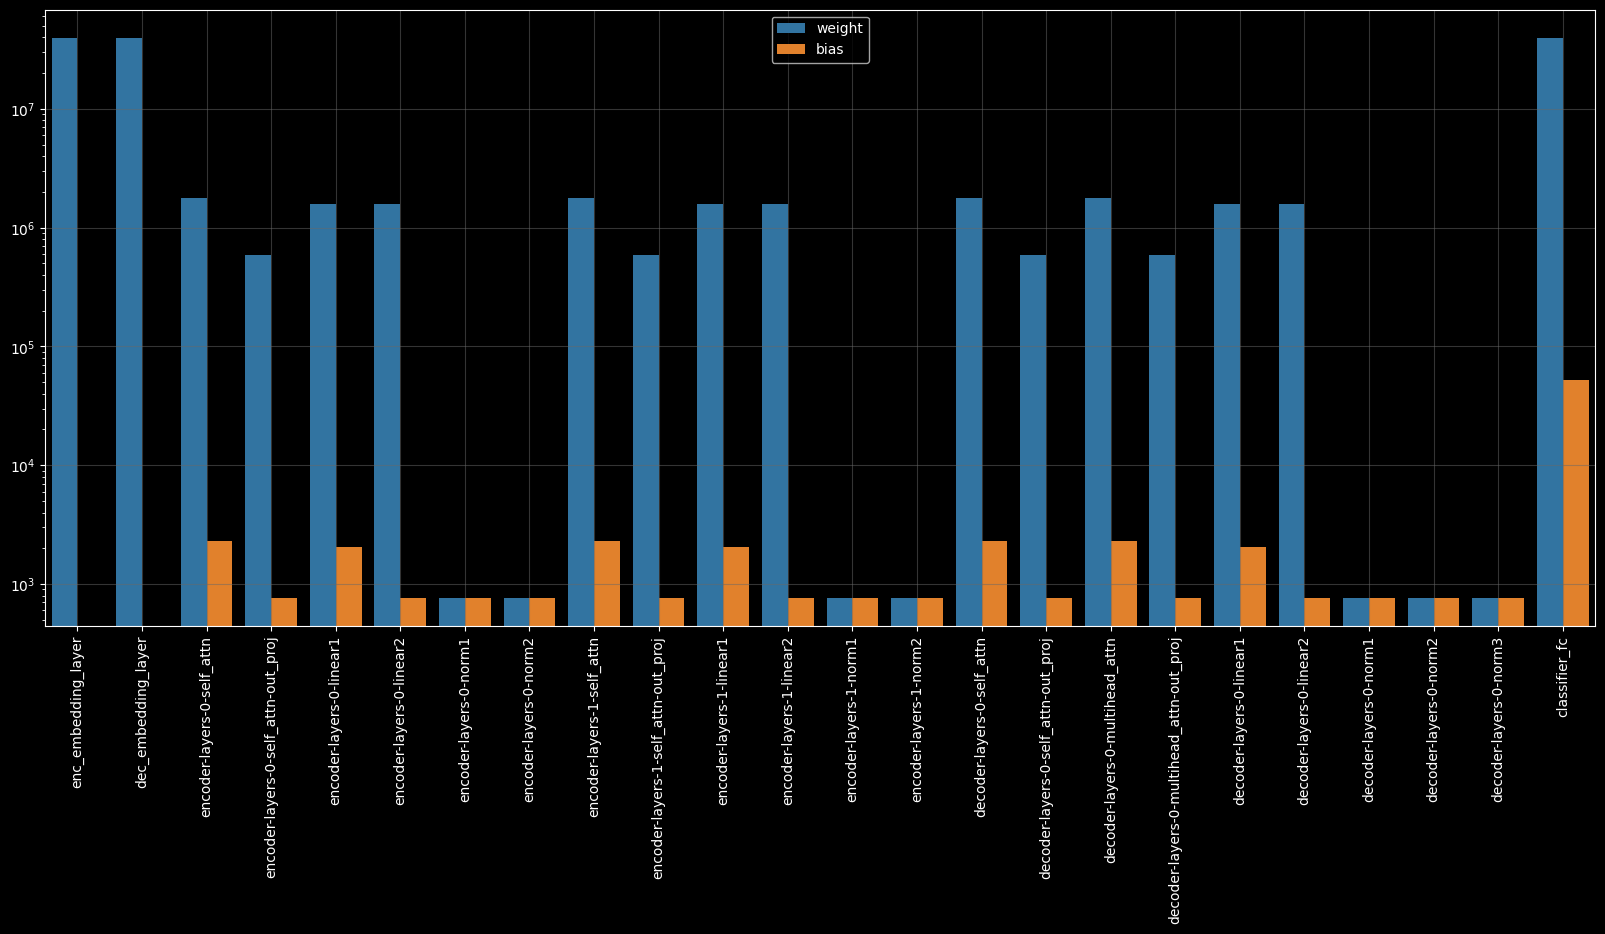

In [25]:
total_param_count = 0
layer_wise_param_count = {"name": [], "param_count": [], "param_type": []}
for name, param in model.named_parameters():
    name_parts = name.split('.')
    layer_name = '-'.join(name_parts[:-1])
    param_count = param.numel()
    param_type = 'weight' if 'weight' in name_parts[-1] else 'bias'
    layer_wise_param_count["name"].append(layer_name)
    layer_wise_param_count["param_count"].append(param_count)
    layer_wise_param_count["param_type"].append(param_type)
    total_param_count += param.numel()

print(f"Model capacity: {total_param_count} or {total_param_count/1000000} million parameters")

plt.figure(figsize=(20, 8))
sns.barplot(x=layer_wise_param_count["name"], y=layer_wise_param_count["param_count"],
           hue=layer_wise_param_count['param_type'], palette='tab10', errorbar=('ci', False))
plt.xticks(rotation=90)
plt.yscale('log')
plt.grid(color='dimgrey', alpha=0.5)
plt.show()

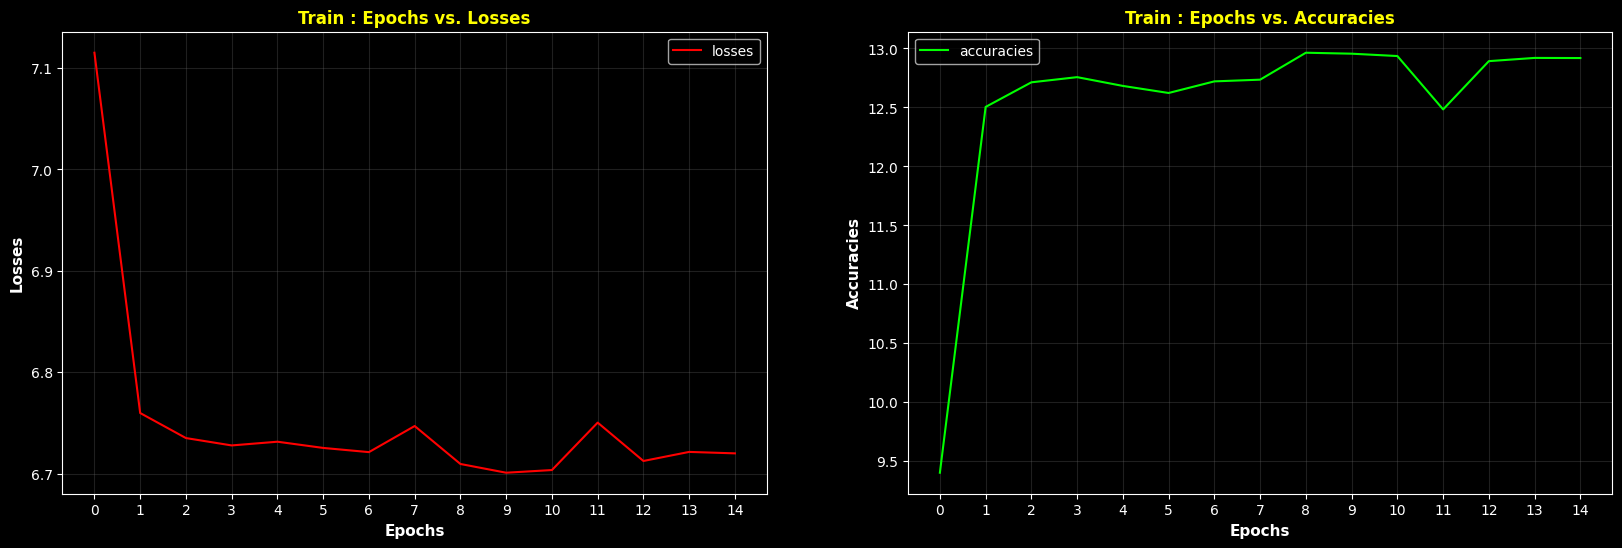

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
training_metrics = metrics["train"]
sns.lineplot(x=training_metrics["epochs"], y=training_metrics["losses"], ax=ax[0], color='red', label='losses')
sns.lineplot(x=training_metrics["epochs"], y=np.array(training_metrics["accuracies"])*100, ax=ax[1], color='lime', label='accuracies')
ax[0].set_xticks(training_metrics["epochs"])
ax[1].set_xticks(training_metrics["epochs"])
ax[0].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[0].set_ylabel("Losses", fontdict={"size": 11, "weight": "bold"})
ax[1].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[1].set_ylabel("Accuracies", fontdict={"size": 11, "weight": "bold"})
ax[0].set_title("Train : Epochs vs. Losses", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[1].set_title("Train : Epochs vs. Accuracies", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[0].grid(color='dimgrey', alpha=0.3)
ax[1].grid(color='dimgrey', alpha=0.3)
plt.legend()
plt.show()

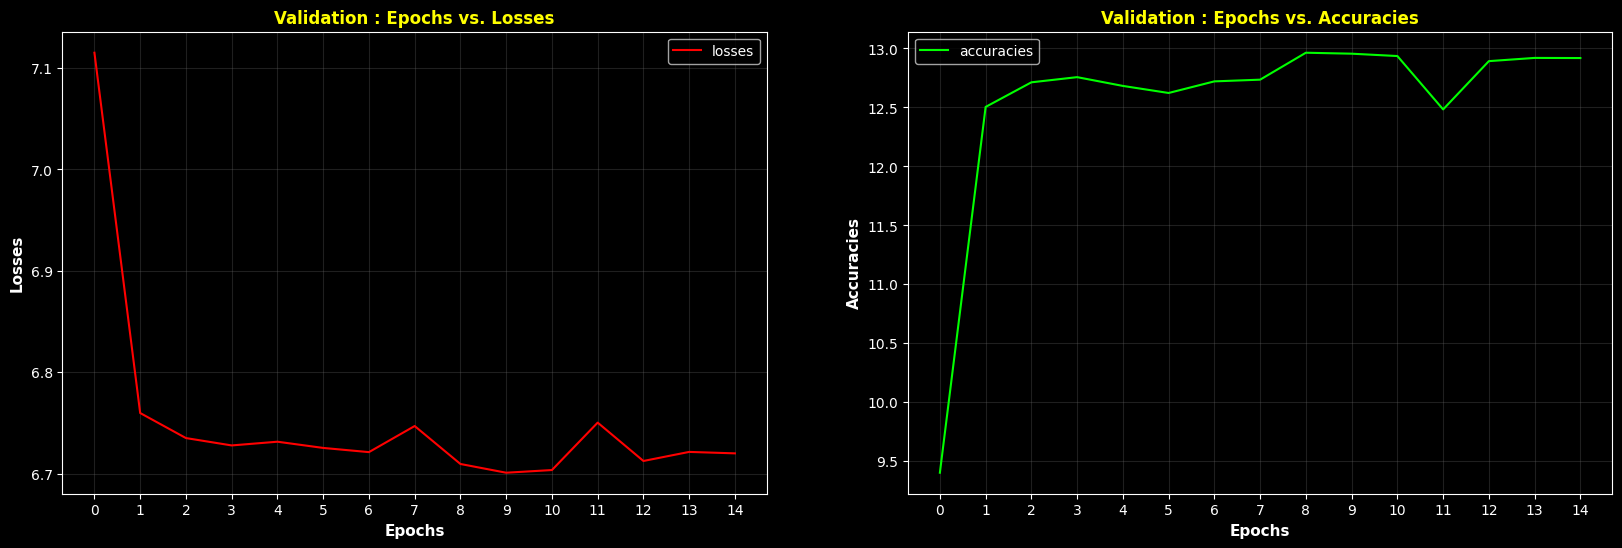

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
val_metrics = metrics["validation"]
sns.lineplot(x=val_metrics["epochs"], y=val_metrics["losses"], ax=ax[0], color='red', label='losses')
sns.lineplot(x=val_metrics["epochs"], y=np.array(val_metrics["accuracies"])*100, ax=ax[1], color='lime', label='accuracies')
ax[0].set_xticks(val_metrics["epochs"])
ax[1].set_xticks(val_metrics["epochs"])
ax[0].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[0].set_ylabel("Losses", fontdict={"size": 11, "weight": "bold"})
ax[1].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[1].set_ylabel("Accuracies", fontdict={"size": 11, "weight": "bold"})
ax[0].set_title("Validation : Epochs vs. Losses", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[1].set_title("Validation : Epochs vs. Accuracies", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[0].grid(color='dimgrey', alpha=0.3)
ax[1].grid(color='dimgrey', alpha=0.3)
plt.legend()
plt.show()

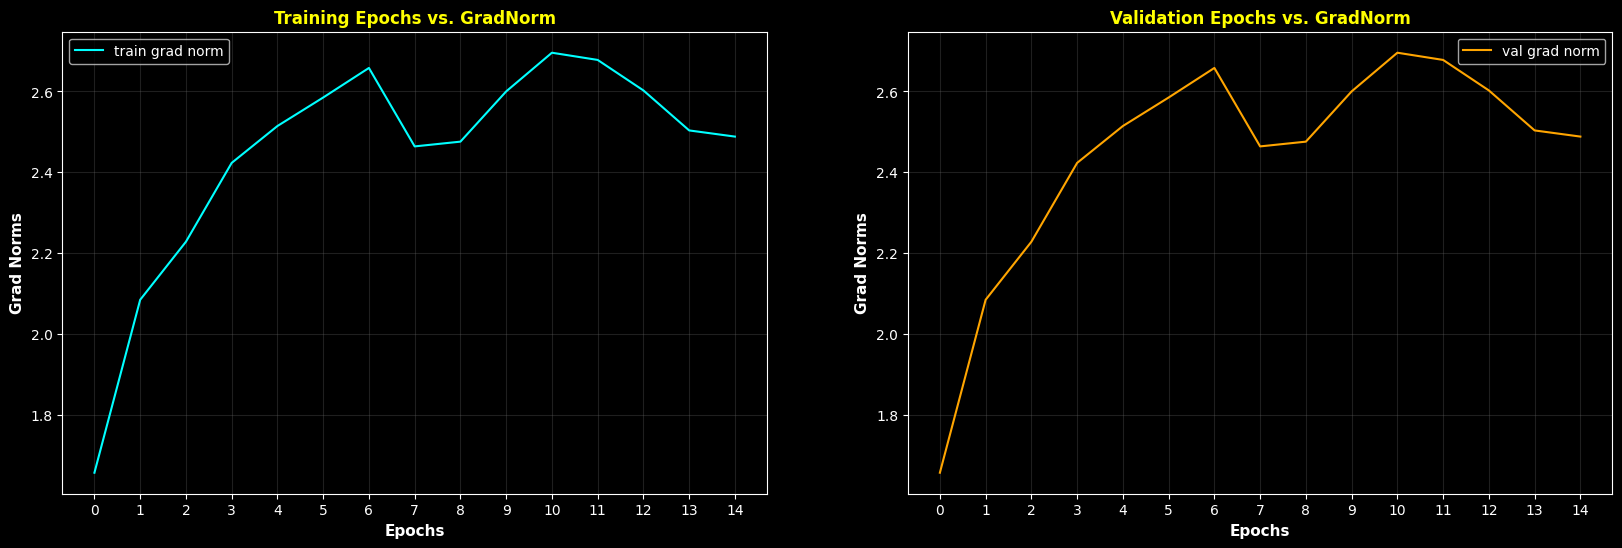

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
sns.lineplot(x=training_metrics["epochs"], y=training_metrics["grad_norms"], color='cyan', label="train grad norm", ax=ax[0])
sns.lineplot(x=val_metrics["epochs"], y=val_metrics["grad_norms"], color='orange', label="val grad norm", ax=ax[1])
ax[0].set_xticks(training_metrics["epochs"])
ax[1].set_xticks(training_metrics["epochs"])
ax[0].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[0].set_ylabel("Grad Norms", fontdict={"size": 11, "weight": "bold"})
ax[1].set_xlabel("Epochs", fontdict={"size": 11, "weight": "bold"})
ax[1].set_ylabel("Grad Norms", fontdict={"size": 11, "weight": "bold"})
ax[0].set_title("Training Epochs vs. GradNorm", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[1].set_title("Validation Epochs vs. GradNorm", fontdict={"size": 12, "weight": "bold", "color": "yellow"})
ax[0].grid(color='dimgrey', alpha=0.3)
ax[1].grid(color='dimgrey', alpha=0.3)
plt.legend()
plt.show()

In [ ]:
def render_config(config_dict: dict):
    def _render_recursive(d: dict, current_indent: str):
        if not d:
            return

        # Calculate maximum key length only for the current nesting level
        max_key_len = max(len(str(k)) for k in d.keys())

        for k, v in d.items():
            # Pad the key locally within its own level
            padded_key = str(k).ljust(max_key_len)

            if isinstance(v, dict):
                # Print the key, opening bracket, and dive into recursion
                print(f"{current_indent}{padded_key} : {{")

                # New indent adds the current padding, the separator " : ", and 2 spaces for the bracket
                next_indent = current_indent + " " * (max_key_len + 3) + "  "
                _render_recursive(v, next_indent)

                # Close the bracket exactly aligned with the child items
                closing_indent = current_indent + " " * (max_key_len + 3)
                print(f"{closing_indent}}}")
            else:
                print(f"{current_indent}{padded_key} : {v}")

    _render_recursive(config_dict, current_indent="")


def format_config_keys(config_dict):

    def format_nested_keys(config_dict):
        for key, val in list(config_dict.items()):
            if isinstance(val, dict):
                format_config_keys(val)

            new_key = key.lower().replace(" ", "_")
            if new_key != key:
                config_dict[new_key] = config_dict.pop(key)
        return config_dict

    for key, val in list(config_dict.items()):
        if isinstance(val, dict):
            config_dict[key] = format_nested_keys(val)
        else:
            new_key = key.lower().replace(" ", "_")
            if new_key != key:
                config_dict[new_key] = config_dict.pop(key)

    return config_dict

utc_timestamp = "UTC-"+datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d-%H%M%S-%f")

config_dict = {
    "training": {
        "timestamp": f"{utc_timestamp} UTC",
        "dataset": "FineWeb Edu (10k)",
        "library": f"PyTorch v{torch.__version__}",
        "framework": f"Encoder-Decoder Transformer",
        "device": device.type,
        "tokenizer config": {
            "tokenizer": "WordPiece",
            "special tokens": special_tokens,
            "token count": f"{len(tokens)} tokens",
            "vocab length": f"{len(vocab)} tokens",
        },
        "dataloader config": {
            "train size": f"{data_size} tokens",
            "train perc": f"{round(data_size*100/len(tokens), 2)}%",
            "context window": f"{context_window} tokens",
            "batch size": f"{batch_size}",
            "src shape": f"{input_enc_tensor.shape}",
            "tgt shape": f"{target_enc_tensor.shape}",
            "num batches": f"{int(input_enc_tensor.shape[0]/batch_size)}",
        },
        "model config": {
            "n_embd" : n_embd,
            "enc_n_head": n_head,
            "dec_n_head": n_head
        },
        "num_epochs": max(metrics["train"]["epochs"]),
        "metrics": {
            "min_loss": np.min(metrics["train"]["losses"]).item(),
            "avg_loss": np.mean(metrics["train"]["losses"]).item(),
            "max_loss": np.max(metrics["train"]["losses"]).item(),
            "min_accuracy": np.min(metrics["train"]["accuracies"]).item()*100,
            "avg_accuracy": np.mean(metrics["train"]["accuracies"]).item()*100,
            "max_accuracy": np.max(metrics["train"]["accuracies"]).item()*100,
        },
        "total_time": f"{total_time} seconds" if total_time is not None else 0,
        "tags": ["causal-lm", "transformer", "text-generation"]
    },
    "validation": {
        "timestamp": f"{utc_timestamp} UTC",
        "dataset": "FineWeb Edu (10k)",
        "library": f"PyTorch v{torch.__version__}",
        "framework": f"Encoder-Decoder Transformer",
        "device": device.type,
        "tokenizer config": {
            "tokenizer": "WordPiece",
            "special tokens": special_tokens,
            "token count": f"{len(tokens)} tokens",
            "vocab length": f"{len(vocab)} tokens",
        },
        "dataloader config": {
            "train size": f"{data_size} tokens",
            "train perc": f"{round(data_size*100/len(tokens), 2)}%",
            "context window": f"{context_window} tokens",
            "batch size": f"{batch_size}",
            "src shape": f"{input_enc_tensor.shape}",
            "tgt shape": f"{target_enc_tensor.shape}",
            "num batches": f"{int(input_enc_tensor.shape[0]/batch_size)}",
        },
        "model config": {
            "n_embd" : n_embd,
            "enc_n_head": n_head,
            "dec_n_head": n_head
        },
        "num_epochs": max(metrics["val"]["epochs"]),
        "metrics": {
            "min_loss": np.min(metrics["val"]["losses"]).item(),
            "avg_loss": np.mean(metrics["val"]["losses"]).item(),
            "max_loss": np.max(metrics["val"]["losses"]).item(),
            "min_accuracy": np.min(metrics["val"]["accuracies"]).item()*100,
            "avg_accuracy": np.mean(metrics["val"]["accuracies"]).item()*100,
            "max_accuracy": np.max(metrics["val"]["accuracies"]).item()*100,
        },
        "total_time": f"{total_time} seconds" if total_time is not None else 0,
        "tags": ["causal-lm", "transformer", "text-generation"]
    }
}

import json
file_path = r"/kaggle/working/config.json"
with open(file_path, "w") as f:
    json.dump(config_dict, f)

config_dict = format_config_keys(config_dict)
render_config(config_dict)

In [ ]:
test_sentence = "Last week, the tallest mountain in North America not only was renamed, but also lost a bit of stature — 10 feet. The United States Geological Survey announced Wednesday that the official height of Denali, the Alaskan mountain formerly known as Mount McKinley, is 20,310 feet. Previously, it was listed at 20,320 feet. The mountain itself has not shrunk, of course. The old elevation was measured in 1953 using optical surveying techniques, and the new elevation reflects the refining of technology. In some respects, the new number marks a rebound. Two years ago, sophisticated airborne radar measurements by the geological survey suggested that Denali was only 20,237 feet, a downward revision of 83 feet. However, while radar excels at revealing the patterns of topography, it does not precisely measure the elevation of specific spots, especially in steep terrain, and the official elevation remained at 20,320 feet. To come up with a conclusive height, a team of four scientists climbed to the summit in June carrying GPS equipment. We wanted to be as accurate as possible, said Mark Newell, a spokesman for the geological survey, which is updating brochures, signs and other materials. Introduction paragraph in essay writing. Parts of an essay — traditionally, it has been taught that a formal essay consists of three parts: the introductory paragraph or introduction, the body paragraphs. The introductory paragraph of any paper, long or short, should start with a sentence that piques the interest of your readers in a well-constructed first paragraph, that first sentence will lead into details."

test_sentence_tokenized = wordpunct_tokenize(test_sentence)[-256:]

test_sentence_encoding = [token2idx[token] for token in test_sentence_tokenized]

test_Xsrc = torch.tensor(np.array(test_sentence_encoding), dtype=torch.long).unsqueeze(0)

model.eval()
with torch.no_grad():
    # 1. Start with your Beginning-of-Sentence token ID (e.g., 1 or whatever your BOS id is)
    # Adjust vocab['<BOS>'] to match your token2idx mapping
    bos_token = 'We'
    bos_id = token2idx[bos_token]

    # Initialize current_tokens as a 2D tensor with a batch size of 1: shape [1, 1]
    current_tokens = torch.tensor([[bos_id]], dtype=torch.long, device=device)

    # Move source sentence to device once
    test_Xsrc = test_Xsrc.to(device)

    # Decode step-by-step
    for n in range(0, 40):
        # Forward pass: model expects shapes [1, src_len] and [1, tgt_len]
        logits, enc_wa, dec_Wa = model(test_Xsrc, current_tokens)

        # We only care about the prediction of the VERY LAST token generated
        # Shape changes from [1, current_seq_len, vocab_size] to [vocab_size]
        last_token_logits = logits[0, -1, :]
        # print(f"last_token_logits shape: {logits.shape, last_token_logits.shape}")

        # Get the single highest probability token ID
        # next_token_id = torch.argmax(last_token_logits, dim=-1, keepdim=True) # shape: [1]

        temperature = max(1.2, 1e-5)

        # 2. Scale the logits by the temperature
        scaled_logits = last_token_logits / temperature

        # 3. Convert the scaled logits into probabilities
        probabilities = F.softmax(scaled_logits, dim=-1)

        # 4. Sample a token ID based on the probability distribution
        # num_samples=1 pulls a single token index from the multinomial distribution
        next_token_id = torch.multinomial(probabilities, num_samples=1)

        # Append the new token ID to our running sequence along the sequence dimension (dim=1)
        # current_tokens grows: [1, 1] -> [1, 2] -> [1, 3]...
        current_tokens = torch.cat([current_tokens, next_token_id.unsqueeze(0)], dim=-1)

        # Break early if the model outputs the End-of-Sentence token
        if next_token_id.item() == token2idx.get('<EOS>', -1):
            break

    # 2. Convert the entire accumulated tensor back to readable words
    # Remove the batch dimension and convert to a basic Python list of numbers
    final_token_ids = current_tokens[0].cpu().numpy().tolist()

    # Translate numbers back to strings, skipping the initial <BOS> token if you want
    generated_words = [idx2token[idx] for idx in final_token_ids[1:]]
    generated_text = bos_token + ' ' + ' '.join(generated_words)

    print(f"Generated Output: {generated_text}")